# Hangman strategy explorer

Compare the hangman strategies from `strategy.py`, `optimal.py` and `winprob.py`
on one word length under a chosen word distribution. Pick a `LENGTH`, a
`WEIGHTING` (how likely each word is to be the secret word) and a `STRATEGY`,
then re-run the rest: the opener, hardest words, per-guess tree, and how the
headline number scales with length all follow your choice.

Reminders: a *miss* is a wrong letter guess. `optimal`/`winprob` replay the
solvers' committed trees, so they only cover length/weighting combinations that
have already been solved -- others report cleanly instead of erroring.

In [1]:
from pathlib import Path
import sys

def find_math_dir():
    cwd = Path.cwd().resolve()
    for c in (cwd, cwd.parent, cwd.parent.parent, cwd / 'math', cwd.parent / 'math'):
        if (c / 'strategy.py').exists():
            return c
    raise FileNotFoundError('Could not find strategy.py. Open from the repo root, math/, or math/notebooks/.')

math_dir = find_math_dir()
if str(math_dir) not in sys.path:
    sys.path.insert(0, str(math_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import strategy
import strategy_view as sview
import wordlist

print(f'imported strategy + strategy_view from {math_dir}')

imported strategy + strategy_view from /Users/patrickliscio/My Documents/Pycharm Projects/Ballpark-Figures/hangman/math


## Pick length, distribution, and strategy

Change `LENGTH`, `WEIGHTING`, `STRATEGY` (and `BUDGET`, for winprob;
`FILL_CAPPED`, for optimal), then re-run the rest.

`WEIGHTING` -- how likely each word is to be the secret word:
- `"uniform"` -- every word equally likely.
- `"zipf"` -- real English frequency (common words weigh more).
- `"greedy"` / `"best_opener"` -- the adversarial word-setter from `freq_search.py`
  (per-(letter,pattern) multipliers), tuned to make that guesser work hardest.
- `"greedy_word"` / `"best_opener_word"` -- the newer *per-word* frequency adversary.

`STRATEGY` -- the guesser:
- `"greedy"` -- guess the highest combined-frequency un-guessed letter (live, any weighting).
- `"greedy_best"` -- force the best first letter, then greedy (live, any weighting).
- `"optimal"` -- minimise expected misses (replays `data/shared/optimal/`).
- `"winprob"` -- maximise P(win within `BUDGET` misses) (replays `data/shared/winprob/`).

`FILL_CAPPED` (optimal only) -- when an optimal solve has **not converged**, its
committed tree truncates the hardest branches at the miss cap (leaves marked
*capped*). With `FILL_CAPPED=True` (default) those branches are finished with
**greedy** -- optimal above the cap, greedy below -- so every word resolves and the
headline `avg_misses` is the *greedy-completed upper bound* on the true optimum
(`summary()['greedy_finished']` counts the completed words). With
`FILL_CAPPED=False` the capped words stay unresolved and the headline averages only
the fully-optimal words (a lower, optimistic partial). Converged solves ignore this
flag (they have no capped branches).

`make_strategy` returns one uniform `sv` that every cell below uses. `optimal`
and `winprob` exist only for solved length/weighting combos; when one is missing,
`sv.available` is `False` and `sv.note` says what to run -- the cells skip cleanly.

In [35]:
LENGTH    = 3           # <-- word length
WEIGHTING = "best_opener_word"   # <-- uniform, zipf, greedy, best_opener, greedy_word, best_opener_word
STRATEGY  = "optimal"    # <-- greedy, greedy_best, optimal, winprob
BUDGET    = None         # <-- winprob only: miss budget k (None = most permissive solved)
FILL_CAPPED = True       # <-- optimal only: finish cap-truncated branches with greedy (see note)

g  = strategy.GreedyGame(LENGTH)
sv = sview.make_strategy(STRATEGY, LENGTH, weighting=WEIGHTING, budget=BUDGET,
                         fill_capped=FILL_CAPPED, game=g)

print(f'{g.N:,} words of length {LENGTH}  (zipf >= {wordlist.DEFAULT_ZIPF})')
print(f'weighting: {WEIGHTING}   strategy: {sv.label}')
if not sv.available:
    print(f'\n!! not available: {sv.note}')
else:
    print(f'opener: {sv.opener()!r}')
    hv = sv.headline_value()
    print(f'{sv.headline_label()}: ' + (f'{hv:.4f}' if hv is not None else 'n/a'))
    for k, v in sv.summary().items():
        print(f'  {k}: {v}')
    if sv.note:
        print(f'note: {sv.note}')

640 words of length 3  (zipf >= 2.5)
weighting: best_opener_word   strategy: optimal (best_opener_word, cap 5*+greedy)
opener: 'i'
avg misses: 7.5976
  opener: i
  note: capped approximation, greedy-completed: deepest committed cap is 5; branches truncated at the cap are finished with greedy (optimal above the cap, greedy below), so every word resolves. The headline avg is the greedy-completed UPPER bound on the true optimum (optimal.py's `upper` column); the true optimum is <= it. Set FILL_CAPPED=False for the raw capped view.
  avg_misses: 7.5975695255900915
  capped: 0
  greedy_finished: 486
note: capped approximation, greedy-completed: deepest committed cap is 5; branches truncated at the cap are finished with greedy (optimal above the cap, greedy below), so every word resolves. The headline avg is the greedy-completed UPPER bound on the true optimum (optimal.py's `upper` column); the true optimum is <= it. Set FILL_CAPPED=False for the raw capped view.


## Best opening letters

Expected misses if each letter is forced as the first guess and the guesser plays
on; the dashed line marks the best (its own opener). This forced-opener sweep is
greedy-family only -- for `optimal`/`winprob` it would need a re-solve per opener
(not cached), so those print a short note instead.

In [36]:
by_letter = sv.misses_by_starting_letter() if sv.available else None
if by_letter is None:
    print(f'{sv.label}: forced-opener sweep is greedy-family only.')
    if sv.available:
        print(f'(this strategy opens with {sv.opener()!r})')
else:
    mb = pd.Series(by_letter, name='avg_misses'); mb.index.name = 'first_letter'
    op = sv.opener()
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.bar(mb.index, mb.values, color='#3b6ea5')
    ax.axhline(mb[op], color='#cc4444', ls='--', lw=1, label=f'{sv.label} opener {op!r}')
    ax.set_ylabel('avg misses')
    ax.set_title(f'Expected misses by opening letter (length {LENGTH}, {WEIGHTING})')
    ax.legend(); plt.show()
    display(mb.to_frame().T)

optimal (best_opener_word, cap 5*+greedy): forced-opener sweep is greedy-family only.
(this strategy opens with 'i')


## Per-word difficulty

How many misses the strategy makes on each word, and the distribution. Words the
strategy leaves *unresolved* -- `optimal` words capped past the solved depth, or
`winprob` words that can't be won within the budget -- have no finite miss count
and are tallied separately (they sort to the top of the hardest list).

solved with 0 misses: 7 words
max misses: 19   mean (resolved): 7.942
greedy-completed (capped branch finished with greedy): 486 words


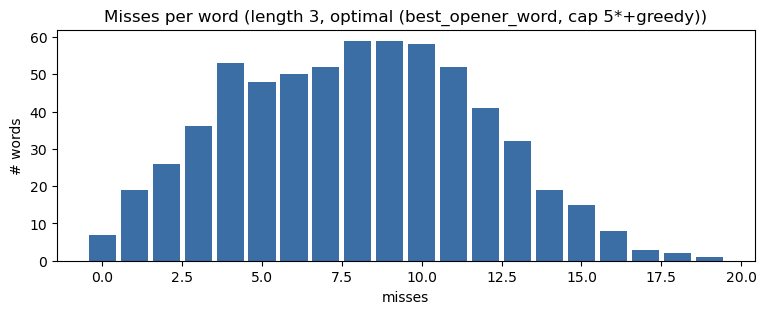

hardest words:


,word,misses
0,the,19.0
1,she,18.0
2,out,18.0
3,top,17.0
4,our,17.0
5,vac,17.0
6,ton,16.0
7,alt,16.0
8,quo,16.0
9,gag,16.0


In [37]:
if not sv.available:
    print('not available:', sv.note)
else:
    pwm = sv.per_word_misses()
    status = sv.per_word_status()
    resolved = pwm[~np.isnan(pwm)]
    n_unres = int(np.isnan(pwm).sum())
    words = pd.DataFrame({'word': g.words, 'misses': pwm})

    print(f'solved with 0 misses: {int((resolved == 0).sum()):,} words')
    hi = int(resolved.max()) if resolved.size else 0
    print(f'max misses: {hi}   mean (resolved): {resolved.mean():.3f}')
    if n_unres:
        kind = 'capped' if sv.kind == 'optimal' else 'lost (over budget)'
        print(f'unresolved ({kind}): {n_unres:,} words')
    n_greedy = int((status == 3).sum())
    if n_greedy:
        print(f'greedy-completed (capped branch finished with greedy): {n_greedy:,} words')

    fig, ax = plt.subplots(figsize=(9, 3))
    if resolved.size:
        ax.hist(resolved, bins=range(0, hi + 2), color='#3b6ea5', align='left', rwidth=0.85)
    ax.set_xlabel('misses'); ax.set_ylabel('# words')
    ax.set_title(f'Misses per word (length {LENGTH}, {sv.label})')
    plt.show()

    print('hardest words:')
    display(words.sort_values('misses', ascending=False, na_position='first')
                 .head(12).reset_index(drop=True))

## Trace one word

The actual guess sequence for a word under the current strategy: each guess and
whether it hit. Defaults to the hardest resolved word; set `WORD` yourself to
trace another.

In [38]:
if not sv.available:
    print('not available:', sv.note)
else:
    pwm = sv.per_word_misses()
    WORD = g.words[int(np.argsort(np.where(np.isnan(pwm), -1.0, pwm))[-1])]  # hardest resolved
    # WORD = 'bench'   # <-- or pick your own

    hits = sv.trace(WORD)
    n_miss = sum(1 for _, hit in hits if not hit)
    print(f'{WORD!r}: {n_miss} misses  ({sv.label})')
    for letter, hit in hits:
        print(f'  {letter}  ' + ('hit ' if hit else 'MISS'))
    if not hits:
        print('  (the strategy leaves this word unresolved)')

'the': 19 misses  (optimal (best_opener_word, cap 5*+greedy))
  i  MISS
  e  hit 
  o  MISS
  a  MISS
  y  MISS
  u  MISS
  b  MISS
  c  MISS
  d  MISS
  f  MISS
  g  MISS
  h  hit 
  j  MISS
  k  MISS
  l  MISS
  m  MISS
  n  MISS
  p  MISS
  q  MISS
  r  MISS
  s  MISS
  t  hit 


## Inspect a tree node

Give a board (revealed letters + `_` blanks, e.g. `"b_ll_"`) and the missed
letters; `show_state` finds that node in the current strategy's tree: the
candidates remaining, the next guess, and every outcome it can produce. States
the strategy never reaches are flagged. A hit reveals **all** positions of a
letter, so put every occurrence of a revealed letter on the board.

In [47]:
def show_state(board, missed=""):
    """Locate `board` (+ missed letters) in the current strategy `sv`'s tree and
    print its next guess and every outcome that guess can lead to."""
    if not sv.available:
        print('not available:', sv.note); return None
    st = sv.state(board, missed)
    tag = 'reachable' if st.get('reachable') else 'NOT REACHED'
    print(f"board {st['board']!r}   missed [{','.join(st['missed'])}]   ({tag})  [{sv.label}]")
    if not st.get('reachable'):
        print(f"  {st.get('reason')}"); return st
    if st['determined']:
        w = st['candidates'][0] if st['candidates'] else '(none)'
        print(f"  word determined: {w}"); return st
    print(f"  {st['n']} candidates, e.g. {', '.join(st['candidates'][:8])}")
    print(f"  guesses: {st['guess']!r}")
    for o in st['outcomes']:
        kind = 'HIT ' if o['hit'] else 'miss'
        print(f"    {kind} -> {o['board']!r}  ({o['n']:>4} words)  e.g. {', '.join(o['sample'][:5])}")
    return st

# the opener: the outcomes of the strategy's first guess (empty board)
_ = show_state('___', 'i')

board '___'   missed [i]   (reachable)  [optimal (best_opener_word, cap 5*+greedy)]
  523 candidates, e.g. the, and, for, you, was, are, not, but
  guesses: 'e'
    miss -> '___'  ( 375 words)  e.g. and, for, you, was, not
    HIT  -> 'e__'  (  21 words)  e.g. end, eat, era, egg, ear
    HIT  -> '_e_'  (  78 words)  e.g. her, get, new, few, let
    HIT  -> 'ee_'  (   1 words)  e.g. eel
    HIT  -> '__e'  (  34 words)  e.g. the, are, one, she, use
    HIT  -> 'e_e'  (   5 words)  e.g. eye, eve, ere, ewe, eke
    HIT  -> '_ee'  (   9 words)  e.g. see, lee, fee, bee, pee


## All situations at depth k

Every node the strategy can reach after exactly `k` guesses, with the choice it
makes there. Depth 0 is the opener; at depth `k`, `k` guesses are in and `guess`
is the next one. Branches already resolved by depth `k` show `guess = None`.

In [48]:
DEPTH = 3      # <-- number of guesses already made

if not sv.available:
    print('not available:', sv.note); sit = pd.DataFrame()
else:
    sit = pd.DataFrame(sv.states_at_depth(DEPTH))
    if len(sit):
        sit['missed'] = sit['missed'].apply(''.join)
        sit['sample'] = sit['sample'].apply(lambda s: ' '.join(s[:4]))
        live = sit[~sit['determined']]
        print(f'depth {DEPTH}: {len(sit)} nodes  ({len(live)} still undetermined)  [{sv.label}]')
        if len(live):
            spread = ', '.join(f'{k}={v}' for k, v in live['guess'].value_counts().items())
            print(f'next guess spread: {spread}')
        display(sit.sort_values('n', ascending=False).head(50).reset_index(drop=True))
    else:
        print(f'no nodes at depth {DEPTH}')

depth 3: 35 nodes  (21 still undetermined)  [optimal (best_opener_word, cap 5*+greedy)]
next guess spread: o=3, s=3, f=3, y=2, w=2, x=1, r=1, v=1, a=1, z=1, n=1, d=1, u=1


,board,missed,n,determined,guess,sample
0,___,eil,338,False,o,and for you was
1,_i_,gm,73,False,z,his did win air
2,_e_,im,69,False,v,her get new few
3,__e,io,22,False,a,the are she use
4,l__,ei,20,False,x,lot law low lay
5,e__,ai,18,False,o,end egg ego eds
6,i__,ln,9,False,y,its ice ivy icy
7,_l_,ei,8,False,y,old fly flu alt
8,__l,ei,8,False,o,vol cal pal col
9,_ee,it,8,False,s,see lee fee bee


In [49]:
sit['guess'].value_counts() if len(sit) else 'no nodes at this depth'

o    3
s    3
f    3
y    2
w    2
x    1
r    1
v    1
a    1
z    1
n    1
d    1
u    1
Name: guess, dtype: int64

## Guess frequency at a level (across all word lengths)

`guesses_at_level(level)` tallies, over **every word length**, how often each
letter is the strategy's next guess at a given `level` (= depth, guesses already
made: `level=0` is the opener, `level=1` the second guess, ...). One row per
letter, sorted by words covered:

- **n_situations** -- how many distinct reachable boards (across all lengths)
  prompt that letter as the next guess at this level,
- **n_words** -- total words those situations cover,
- **situations** -- every such board, labelled `len:board[/missed] (words)` and
  sorted by words covered (descending).

Uses the current `STRATEGY`/`WEIGHTING`/`BUDGET`/`FILL_CAPPED`; word lengths with
no committed solve for this strategy are skipped cleanly. Determined branches
(word already known, so no guess) are not counted.

In [ ]:
LEVEL = 1        # <-- guesses already made: 0 = opener, 1 = second guess, ...

def guesses_at_level(level, lengths=range(1, 21), *, strategy=STRATEGY,
                     weighting=WEIGHTING, budget=BUDGET, fill_capped=FILL_CAPPED):
    """Per-letter tally of the strategy's next guess at `level`, aggregated across
    every word length. One row per letter with the number of situations (reachable
    boards) that prompt it, the words those situations cover, and the situations
    themselves (`len:board[/missed] (words)`) sorted by words covered, descending.
    Lengths with no committed solve for this strategy are skipped; determined
    branches (no guess) are ignored."""
    rows = {}
    for L in lengths:
        s = sview.make_strategy(strategy, L, weighting=weighting, budget=budget,
                                fill_capped=fill_capped)
        if not s.available:
            continue
        for st in s.states_at_depth(level):
            if st['determined']:
                continue
            missed = ''.join(st['missed'])
            label = f"{L:>2}:{st['board']}" + (f"/{missed}" if missed else "")
            rows.setdefault(st['guess'], []).append((label, st['n']))
    out = []
    for letter, sits in rows.items():
        sits.sort(key=lambda t: t[1], reverse=True)
        out.append({'letter': letter,
                    'n_situations': len(sits),
                    'n_words': sum(n for _, n in sits),
                    'situations': [f'{lab} ({n})' for lab, n in sits]})
    if not out:
        return pd.DataFrame(columns=['letter', 'n_situations', 'n_words', 'situations'])
    return (pd.DataFrame(out).sort_values('n_words', ascending=False)
              .reset_index(drop=True))

tbl = guesses_at_level(LEVEL)
print(f'level {LEVEL} (guess #{LEVEL + 1}): {len(tbl)} distinct letters  '
      f'[{STRATEGY} / {WEIGHTING}]')
with pd.option_context('display.max_colwidth', None):
    display(tbl)

## Headline metric by length

How the current strategy's headline number -- avg misses, or P(win<=k) for
winprob -- scales across word lengths under the chosen `WEIGHTING`. Lengths with
no committed `optimal`/`winprob` solve are left as gaps.

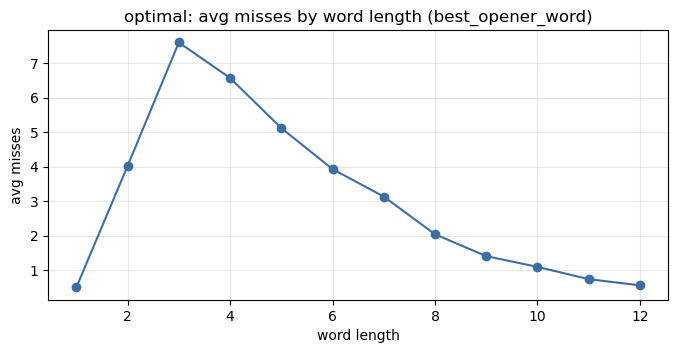

,length,avg misses
0,1,0.500
1,2,4.021
2,3,7.598
3,4,6.569
4,5,5.119
5,6,3.928
6,7,3.133
7,8,2.041
8,9,1.408
9,10,1.096


In [42]:
lengths = list(range(1, 13))
vals = []
for L in lengths:
    s = sview.make_strategy(STRATEGY, L, weighting=WEIGHTING, budget=BUDGET,
                            fill_capped=FILL_CAPPED)
    vals.append(s.headline_value() if s.available else np.nan)
metric = sv.headline_label() if sv.available else 'metric'

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(lengths, vals, 'o-', color='#3b6ea5')
ax.set_xlabel('word length'); ax.set_ylabel(metric)
ax.set_title(f'{STRATEGY}: {metric} by word length ({WEIGHTING})')
ax.grid(alpha=0.3); plt.show()

def _fmt(v):
    return None if v is None or (isinstance(v, float) and np.isnan(v)) else round(v, 3)
pd.DataFrame({'length': lengths, metric: [_fmt(v) for v in vals]})